# Angular Bias Audit in TransparentGS
**Universidad Nacional Mayor de San Marcos · Doctoral Program in Deep Tech**  
**Research Methods and Scientific Integrity in AI · Session 12**  
**Professor:** Dr. Loveleen Gaur  
**Researcher:** Edward Alexander Fuentes Aliaga  
**Experiment:** November 26, 2026 · `apple20` scene

## Purpose of this notebook
This notebook is a study and presentation resource. It also allows the analysis performed during the audit to be reproduced. It distinguishes between *measuring* a performance gap, *changing* the training process, and *demonstrating* an improvement. The results use real evidence, not simulated data.

**Safe mode (the default and only execution mode of this notebook):** read the evidence and recalculate the results on the CPU. The GPU commands used in the research are documented but are not run automatically. The cell outputs come from the analysis of saved files, not from new training runs.

| Block | Content |
|---|---|
| I | Research question, protocol, file inventory and cameras |
| II | Historical reconstruction H, batch M and angular analysis |
| III | Integrity: GT matching, source code and potential data leakage in SDF |
| IV | A1 design, seed control, pilot and paired training |
| V | Optical evaluation, metrics, gaps, images and sensitivity analysis |
| VI | Costs, conclusions, pending requirements and traceability |

**To run again:** extract the entire delivery ZIP and open this notebook next to the `evidencias/` folder. It requires NumPy, pandas, matplotlib, Pillow and scikit-image. No GPU or internet connection is needed. If you open only the `.ipynb` file, you can read the saved results, but you need the evidence package to recalculate them.

**Reading the original labels:** the code, data fields and filenames retain their original names. `Bajo`, `Medio` and `Alto` mean Low, Medium and High. `semilla` means seed, `imagen` means image, `grupo` means group, and `angulo` means angle.

## I.1. Research question and scope
Does the rendering quality of TransparentGS in `apple20` vary systematically with the tilt of the optical axis? Does balanced sampling by group reduce this gap while maintaining reasonable quality and cost?

- **H:** one historical reconstruction and two evaluations (auxiliary Gaussian rendering and adapted optical rendering).
- **M:** five historical pipelines with declared seeds 0, 12, 21, 42 and 123, using the same data split. They are used for exploratory analysis because SDF may have accessed the test data.
- **A0:** a new local baseline without mitigation, with isolated SDF input data.
- **A1:** the same new configuration, with angular balancing in stage 1 and stage 2. It does not include Riemannian optimization or deflectometry.

The attribute being analyzed is an image capture condition, not a protected demographic attribute. The professor's classification exercise is adapted to reconstruction and rendering. Binary labels are not imposed, and neither AIF360 nor the four-fifths rule is applied directly. The main metrics are PSNR, SSIM and LPIPS-Alex, along with their gaps between groups. LPIPS was chosen as the priority after the historical analysis; there was no preregistration. The study does not validate 3D geometric distances or quantitative equivalence to the original paper.

In [1]:
# Imports for the analysis: TransparentGS is not imported and CUDA is not used.
from pathlib import Path, PureWindowsPath
import io, json, hashlib, zipfile, re, sys, platform, difflib, ast
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display, Code, Markdown
import skimage

# The Jupyter working directory must contain the evidence folder.
E = Path.cwd() / 'evidencias'
if not E.is_dir():
    raise FileNotFoundError('Extract the full package and open the notebook next to evidencias/.')
GRUPOS = ['Bajo', 'Medio', 'Alto']
SEMILLAS = [0, 12, 21, 42, 123]
METRICAS = ['psnr','ssim','lpips_alex']
ETAPAS = ['inicial','malla','gaussprobe','sdf','final']
VARIANTES = ['A0','A1']
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
print('CPU analysis mode |', platform.system(), '| Python', sys.version.split()[0])
print('NumPy',np.__version__,'| pandas',pd.__version__,'| scikit-image',skimage.__version__)

CPU analysis mode | Linux | Python 3.13.5
NumPy 2.3.5 | pandas 2.2.3 | scikit-image 0.26.0


## I.2. Evidence inventory and protection
SHA-256 helps verify that the file bytes have not changed from those in the package. The delivery inventory was created when this notebook was built; it does not replace the historical hashes recorded by the controllers. The ZIP files are also checked using CRC, and Windows path separators are standardized only when reading archive entries. Python files inside the ZIP archives are neither extracted nor executed.

In [2]:
# Reusable functions for reading and checking files.
def sha_bytes(data):
    return hashlib.sha256(data).hexdigest()
def leer_json(nombre):
    return json.loads((E/nombre).read_text(encoding='utf-8-sig'))
def leer_csv(nombre, **kwargs):
    return pd.read_csv(E/nombre, encoding='utf-8-sig', **kwargs)
def abrir_zip(nombre):
    z=zipfile.ZipFile(E/nombre)
    assert z.testzip() is None, nombre
    return z

def miembro(z, nombre):
    # PowerShell may generate entry names with backslashes.
    encontrados=[n for n in z.namelist() if n.replace('\\','/')==nombre.replace('\\','/')]
    assert len(encontrados)==1, (nombre,encontrados)
    return z.read(encontrados[0])
def jzip(z,n): return json.loads(miembro(z,n).decode('utf-8-sig'))
def czip(z,n,**kw): return pd.read_csv(io.BytesIO(miembro(z,n)),encoding='utf-8-sig',**kw)
def tzip(z,n): return miembro(z,n).decode('utf-8-sig')
def basename(s): return PureWindowsPath(str(s)).name
def grupo(theta): return 'Bajo' if theta<20 else ('Medio' if theta<40 else 'Alto')

inventario=leer_json('inventario_sha256.json')
control=pd.DataFrame([{'archivo':f,'bytes':v['bytes'],'SHA-256 coincide':sha_bytes((E/f).read_bytes())==v['sha256']} for f,v in inventario.items()])
assert control['SHA-256 coincide'].all()
print(f'{len(control)} evidence files verified.')
display(control[control.archivo.str.endswith('.zip')])
zM=abrir_zip('Auditoria_TGS.zip')
zGT=abrir_zip('Verificacion_GT_TGS_20261126_100632_558869.zip')
zP=abrir_zip('Preparacion_A1_TGS_20261126_101119_386466.zip')
zPi=abrir_zip('Piloto_TGS_20261126_101740_848793.zip')
zC=abrir_zip('Continuacion_TGS_20261126_102811_711790.zip')
zE=abrir_zip('Evaluacion_A0_A1_TGS_20261126_200556_115775.zip')
print('Entries in the six ZIP files:',[len(z.namelist()) for z in [zM,zGT,zP,zPi,zC,zE]])

41 evidence files verified.


,archivo,bytes,SHA-256 coincide
12,Auditoria_TGS.zip,231817,True
13,Verificacion_GT_TGS_20261126_100632_558869.zip,28609,True
14,Preparacion_A1_TGS_20261126_101119_386466.zip,55018,True
15,Piloto_TGS_20261126_101740_848793.zip,832403,True
16,Continuacion_TGS_20261126_102811_711790.zip,530017,True
17,Evaluacion_A0_A1_TGS_20261126_200556_115775.zip,3019595,True


Entries in the six ZIP files: [100, 15, 28, 17, 31, 132]


## I.3. Dataset and angular definition (step 1)
The files `transforms_train.json` and `transforms_test.json` are used. Each `transform_matrix` represents a camera-to-world transformation. The last column contains the position, and the third rotation vector describes the local Z axis. The audit uses the **absolute tilt relative to the XY plane of the dataset**:

$$\theta=\frac{180}{\pi}\operatorname{atan2}(|R_{3,3}|,\sqrt{R_{1,3}^2+R_{2,3}^2}).$$

The Blender convention uses -Z as the viewing direction. Conversion to COLMAP reverses the local Y/Z axes; taking the absolute value preserves the tilt. This is not the elevation of the camera center relative to the object. The limits were set during the initial analysis: low [0,20), medium [20,40), high [40,90]. They were not selected according to performance.

train declared resolution: 811 810 views: 119
test declared resolution: 811 810 views: 17


split,train,test,train_pct,test_pct
grupo,,,,
Bajo,34,3,28.571429,17.647059
Medio,62,8,52.100840,47.058824
Alto,23,6,19.327731,35.294118


,count,min,mean,max
split,,,,
test,17,15.179212,35.043951,70.099568
train,119,4.455938,28.374622,58.335880


Test views above the maximum training angle:


,id,imagen,angulo
0,0,0000,58.389199
6,6,0048,70.099568
11,11,0088,62.569730


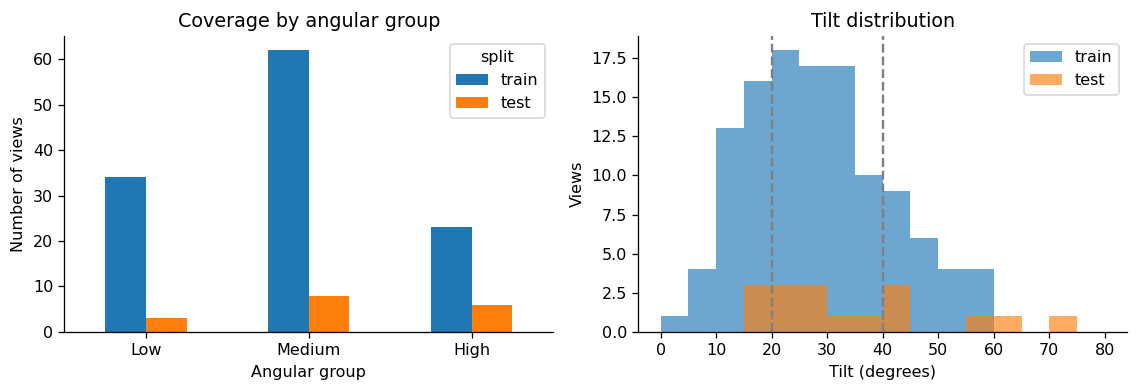

In [3]:
# One row per camera; the original JSON files are not modified.
transforms={split:leer_json(f'transforms_{split}.json') for split in ['train','test']}
poses={}; filas=[]
for split,data in transforms.items():
    print(split,'declared resolution:',data['w'],data['h'],'views:',len(data['frames']))
    for fr in data['frames']:
        nombre=Path(fr['file_path']).stem
        mat=np.array(fr['transform_matrix'],dtype=float)
        assert mat.shape==(4,4) and np.isfinite(mat).all()
        assert np.allclose(mat[3],[0,0,0,1])
        R=mat[:3,:3]; col=R[:,2]; det=np.linalg.det(R)
        error=np.max(np.abs(R.T@R-np.eye(3)))
        assert error<1e-9 and abs(det-1)<1e-9
        assert nombre not in poses, f'Duplicate name: {nombre}'
        poses[nombre]=mat
        theta=np.degrees(np.arctan2(abs(col[2]),np.linalg.norm(col[:2])))
        filas.append({'split':split,'imagen':nombre,'x':mat[0,3],'y':mat[1,3],'z':mat[2,3],
            'angulo':theta,'azimut_eje_z':np.degrees(np.arctan2(col[1],col[0]))%360,'grupo':grupo(theta),'error_ortogonal':error})
camaras=pd.DataFrame(filas)
train=camaras.query("split=='train'").copy(); test=camaras.query("split=='test'").copy().reset_index(drop=True)
test['id']=np.arange(len(test))
assert len(train)==119 and len(test)==17 and len(poses)==136
assert set(train.imagen).isdisjoint(test.imagen)
conteos=pd.crosstab(camaras.grupo,camaras.split).reindex(GRUPOS)[['train','test']]
conteos['train_pct']=conteos.train/len(train)*100
conteos['test_pct']=conteos.test/len(test)*100
display(conteos)
display(camaras.groupby('split').angulo.agg(['count','min','mean','max']))
print('Test views above the maximum training angle:')
display(test.loc[test.angulo>train.angulo.max(),['id','imagen','angulo']])
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
conteos[['train','test']].plot.bar(ax=ax[0],rot=0,title='Coverage by angular group'); ax[0].set_ylabel('Number of views'); ax[0].set_xlabel('Angular group'); ax[0].set_xticks(range(3), ['Low','Medium','High'])
for split,df in [('train',train),('test',test)]:
    ax[1].hist(df.angulo,bins=np.arange(0,81,5),alpha=.65,label=split)
ax[1].axvline(20,color='gray',ls='--'); ax[1].axvline(40,color='gray',ls='--'); ax[1].set(xlabel='Tilt (degrees)',ylabel='Views',title='Tilt distribution'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.** There are 34/62/23 training views and 3/8/6 test views. The high-angle group has the fewest training views, and three test views have a tilt greater than the maximum training tilt. This identifies a coverage risk, but does not show that this group performs worse. The resolution stated in the JSON files alone does not verify the actual image files. Unique filenames do not prove the absence of visually duplicated images.

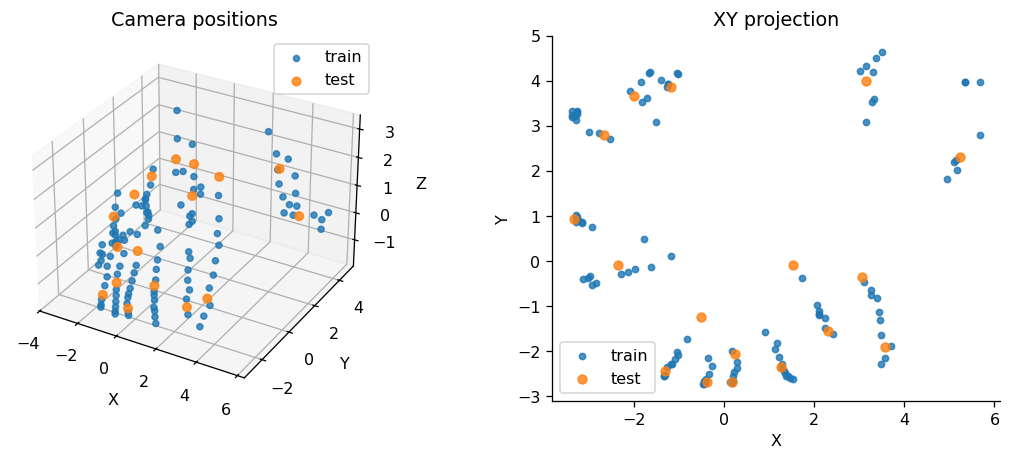

In [4]:
# Visualize camera centers in the dataset coordinate system, not relative to the object center.
fig=plt.figure(figsize=(10,4)); ax=fig.add_subplot(121,projection='3d'); bx=fig.add_subplot(122)
for split,df in [('train',train),('test',test)]:
    ax.scatter(df.x,df.y,df.z,s=14 if split=='train' else 28,label=split,alpha=.8)
    bx.scatter(df.x,df.y,s=15 if split=='train' else 30,label=split,alpha=.8)
ax.set(xlabel='X',ylabel='Y',zlabel='Z',title='Camera positions'); ax.legend()
bx.set(xlabel='X',ylabel='Y',title='XY projection'); bx.set_aspect('equal'); bx.legend()
plt.tight_layout(); plt.show()

## II.1. Recovering historical results H and batch M (steps 2–3)
The initial and optical CSV files of H each contain 17 image pairs. They represent two different types of evaluation, not a mitigation experiment. The standard deviation (SD) of H is measured between views. Batch M completed five pipelines and produced 85 evaluated pairs. The SD of its mean results is measured across five runs, not 85 independent observations. The historical reproducibility reports are included in the package.

In [5]:
# H summary recalculated from the historical CSV files; LPIPS was not recorded for H.
histH=[]
for etiqueta,csvfile,jsonfile in [('H Gaussian','metricas_por_vista.csv','resumen_metricas.json'),('H optical','metricas_por_vista(1).csv','resumen_metricas(1).json')]:
    df=leer_csv(csvfile); ref=leer_json(jsonfile)
    assert len(df)==ref['pares_evaluados']==17
    for m in ['psnr','ssim']:
        media=df[m].mean(); de=df[m].std(ddof=1)
        assert np.isclose(media,ref['resultados'][m]['media'],atol=1e-12,rtol=0)
        assert np.isclose(de,ref['resultados'][m]['desviacion_estandar_muestral'],atol=1e-12,rtol=0)
        histH.append({'evaluacion':etiqueta,'metrica':m,'media':media,'SD across views':de})
display(pd.DataFrame(histH))
parciales=leer_json('resultados_parciales.json'); estad=leer_json('estadisticas_5_semillas.json')
M=pd.DataFrame([{'semilla':x['semilla'],**x['metricas']} for x in parciales]).set_index('semilla')
assert list(M.index)==SEMILLAS
for m in M.columns:
    assert np.isclose(M[m].mean(),estad[m]['media'])
    assert np.isclose(M[m].std(ddof=1),estad[m]['desviacion_estandar_muestral'])
display(M)
display(M.agg(['mean','std','min','max']).T)
print('Mean pipeline time for M (min):',round(M.tiempo_pipeline_s.mean()/60,3))

,evaluacion,metrica,media,SD across views
0,H Gaussian,psnr,12.681684,1.937921
1,H Gaussian,ssim,0.758295,0.063663
2,H optical,psnr,21.516397,1.441103
3,H optical,ssim,0.865310,0.031294


,psnr,ssim,lpips_alex,tiempo_pipeline_s,tiempo_renderizado_s,tiempo_metricas_s,vram_gpu_total_pico_observado_mib
semilla,,,,,,,
0,21.361482,0.861491,0.145127,4560.197648,274.859412,5.646790,7385.000000
12,20.902282,0.856566,0.152555,4900.357501,277.963892,3.587366,7269.000000
21,21.405768,0.863690,0.143655,4751.864494,265.711536,4.822897,10368.000000
42,21.190575,0.858329,0.154632,4939.173819,279.922734,5.106341,8863.000000
123,21.376615,0.862603,0.142719,4807.397921,282.644150,6.396401,10465.000000


,mean,std,min,max
psnr,21.247344,0.210433,20.902282,21.405768
ssim,0.860536,0.002990,0.856566,0.863690
lpips_alex,0.147738,0.005464,0.142719,0.154632
tiempo_pipeline_s,4791.798276,149.148888,4560.197648,4939.173819
tiempo_renderizado_s,276.220345,6.524954,265.711536,282.644150
tiempo_metricas_s,5.111959,1.042090,3.587366,6.396401
vram_gpu_total_pico_observado_mib,8870.000000,1545.679786,7269.000000,10465.000000


Mean pipeline time for M (min): 79.863


## II.2. Validating the cameras and the 85 scripts
The reader `scene/dataset_readers.py` reverses the Y/Z columns of the Blender matrix. This transformation, the camera name, position and order are verified. `cameras.json` contains the test cameras first and the training cameras next. The camera index assigned in each script and the pair CSV files are checked. The scripts are read as text, not executed.

In [6]:
cam0=leer_json('cameras.json')
assert (E/'cameras.json').read_bytes()==(E/'cameras(1).json').read_bytes()
assert len(cam0)==136
orden=list(test.imagen)+list(train.imagen)
assert [c['img_name'] for c in cam0]==orden
for i,c in enumerate(cam0):
    mat=poses[c['img_name']]; R=mat[:3,:3].copy(); R[:,1:3]*=-1
    assert c['id']==i
    assert np.allclose(c['position'],mat[:3,3],atol=1e-10,rtol=0)
    assert np.allclose(c['rotation'],R,atol=1e-10,rtol=0)
print('136 cameras: identity, poses, IDs and coordinate conversion verified.')

def comprobar_pares(df,pares):
    assert len(df)==len(pares)==17
    assert df[['referencia','render']].equals(pares[['referencia','render']])
    ids=df.render.map(lambda p:int(re.search(r'(\d+)\.png$',basename(p)).group(1)))
    ids_gt=df.referencia.map(lambda p:int(Path(basename(p)).stem))
    assert np.array_equal(ids,ids_gt) and set(ids)==set(range(17))
    return ids

historico=[]; normalizados=[]
for s in SEMILLAS:
    pref=f'Semilla_{s}'
    assert miembro(zM,pref+'/cameras.json')==(E/'cameras.json').read_bytes()
    df=czip(zM,pref+'/metricas_por_vista.csv'); pares=czip(zM,pref+'/pares_test_optico.csv')
    df['id']=comprobar_pares(df,pares)
    for i in range(17):
        src=tzip(zM,f'{pref}/vista_{i:02d}.py')
        assert re.search(r'cam\s*=.*?\['+str(i)+r'\]',src)
        assert f'optico_test_{i:02d}.png' in src and f'{i:05d}.png' in src
        assert f'apple20_seed_{s}_20261030_070309_ea9620' in src
        norm=src.replace(f'apple20_seed_{s}_20261030_070309_ea9620','RUN').replace(f'optico_test_{i:02d}.png','RENDER').replace(f'{i:05d}.png','GT')
        norm=re.sub(r'(cam\s*=.*?\[)\d+(\])',r'\1IDX\2',norm)
        normalizados.append(norm)
    for m in METRICAS:
        ref=next(x for x in parciales if x['semilla']==s)['resultados_por_vista']['resultados'][m]
        assert np.isclose(df[m].mean(),ref['media'],atol=1e-12,rtol=0)
        assert np.isclose(df[m].std(ddof=1),ref['desviacion_estandar_muestral'],atol=1e-12,rtol=0)
    df['semilla']=s
    historico.append(df.merge(test[['id','imagen','angulo','grupo']],on='id',validate='one_to_one'))
H85=pd.concat(historico,ignore_index=True)
assert len(H85)==85 and len(set(normalizados))==1
print('85 normalized scripts are identical; pairs and statistics for batch M verified.')
display(H85[['semilla','id','imagen','angulo','grupo']+METRICAS].head(17))

136 cameras: identity, poses, IDs and coordinate conversion verified.
85 normalized scripts are identical; pairs and statistics for batch M verified.


,semilla,id,imagen,angulo,grupo,psnr,ssim,lpips_alex
0,0,0,0000,58.389199,Alto,20.179638,0.868192,0.116801
1,0,1,0008,15.179212,Bajo,21.610781,0.853187,0.147577
2,0,2,0016,24.859468,Medio,21.565807,0.848155,0.144148
3,0,3,0024,40.982745,Alto,21.331496,0.837741,0.162991
4,0,4,0032,16.215645,Bajo,22.453125,0.879957,0.130275
5,0,5,0040,28.898037,Medio,19.616148,0.852117,0.172086
6,0,6,0048,70.099568,Alto,20.614647,0.830039,0.158019
7,0,7,0056,16.716011,Bajo,20.621025,0.856129,0.209153
8,0,8,0064,23.360185,Medio,19.373436,0.784776,0.241529
9,0,9,0072,27.578839,Medio,21.891672,0.850254,0.154932


## II.3. Performance analysis by perspective (step 4)
For each seed, the mean of each group is calculated, not just the overall mean. Higher PSNR and SSIM are better; lower LPIPS is better. The descriptive gap is defined as the maximum minus the minimum of the group means, regardless of the direction of the metric. This value alone cannot show whether the best group became worse. The performance of the worst group must also be considered.

psnr     ssim  lpips_alex
semilla grupo                               
0       Alto  21.757849 0.861348    0.131617
        Bajo  21.561644 0.863091    0.162335
        Medio 20.989145 0.860997    0.148805
12      Alto  21.728392 0.860497    0.131036
        Bajo  20.770861 0.851658    0.185000
        Medio 20.331981 0.855459    0.156528
21      Alto  21.817244 0.862647    0.132865
        Bajo  21.281294 0.862120    0.160406
        Medio 21.143839 0.865062    0.145466
42      Alto  21.850000 0.862322    0.138767
        Bajo  20.701196 0.851604    0.182345
        Medio 20.879523 0.857856    0.156138
123     Alto  21.848634 0.863420    0.128363
        Bajo  21.239156 0.860119    0.164308
        Medio 21.074148 0.862921    0.145391

psnr              ssim          lpips_alex         
           mean      std     mean      std       mean      std
grupo                                                         
Bajo  21.110830 0.364739 0.857718 0.005660   0.170879 0.011798
Medio 20.883727 0.323834 0.860459 0.003851   0.150466 0.005533
Alto  21.800424 0.054923 0.862047 0.001142   0.132530 0.003855

,psnr,ssim,lpips_alex
semilla,,,
0,0.768703,0.002094,0.030718
12,1.396412,0.008839,0.053964
21,0.673406,0.002942,0.027541
42,1.148804,0.010718,0.043578
123,0.774486,0.003301,0.035945


,psnr,ssim,lpips_alex
mean,0.952362,0.005579,0.038349
std,0.307797,0.003916,0.010630


LPIPS order low > medium > high: 5 out of 5 seeds
Relative difference: low vs. high (%): 28.936433957008024


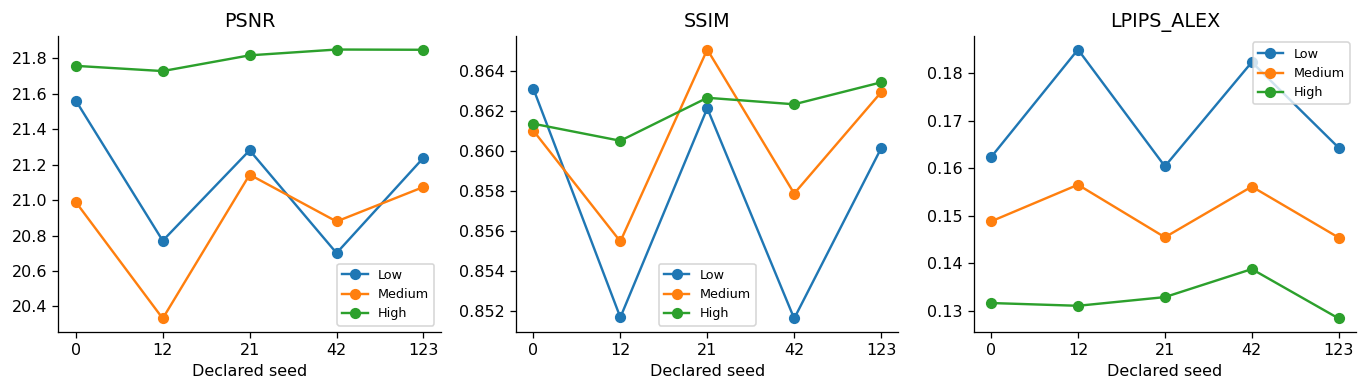

In [7]:
gM=H85.groupby(['semilla','grupo'])[METRICAS].mean()
M_grupos=gM.groupby('grupo').agg(['mean','std']).reindex(GRUPOS)
display(gM); display(M_grupos)
bM=gM.groupby('semilla').max()-gM.groupby('semilla').min()
display(bM); display(bM.agg(['mean','std']))
lp=gM.lpips_alex.unstack().reindex(columns=GRUPOS)
print('LPIPS order low > medium > high:',int(((lp.Bajo>lp.Medio)&(lp.Medio>lp.Alto)).sum()),'out of 5 seeds')
print('Relative difference: low vs. high (%):',100*(lp.Bajo.mean()/lp.Alto.mean()-1))
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for m,ax in zip(METRICAS,axes):
    g=gM[m].unstack().reindex(columns=GRUPOS)
    for name in GRUPOS: ax.plot([str(s) for s in g.index],g[name],marker='o',label={'Bajo':'Low','Medio':'Medium','Alto':'High'}[name])
    ax.set(title=m.upper(),xlabel='Declared seed'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Exploratory finding:** LPIPS is higher for low angles than medium angles, and higher for medium angles than high angles, in 5/5 runs. Mean LPIPS for low angles is about 29% higher than for high angles. The medium group has the lowest mean PSNR. The lower frequency of the high-angle group does not directly explain performance. Five seeds on one fixed split are not five data splits. The audit also found an SDF risk that prevents the use of M as a clean control for A1.

## III.1. Integrity of the ground truth (GT) references
`Scene` saves the cameras before `random.shuffle`. Matching metadata is not enough to confirm that the image pixels correspond to the correct camera. On the laptop, `verificar_GT_TGS.py` reconstructed each candidate image using its mask and compared the mean absolute error (MAE) of each GT image against the 17 candidates, with black and white backgrounds. The identification is recalculated below from the saved MAE matrix. The original candidates are not recreated here because not all source RGB images and masks are included.

Expected matches: 17 | Exact RGB matches: 0
Best MAE: minimum, mean, maximum: {'min': 0.091824281862596, 'mean': 0.13713434288146925, 'max': 0.2696507125625899}
Minimum MAE of the second candidate: 11.408633866488271


,gt,imagen_esperada,imagen_mas_parecida,mae_mejor,mae_segunda_imagen,ancho_gt,alto_gt
0,00000.png,0000,0000,0.096838,14.225058,406,405
1,00001.png,0008,0008,0.149679,11.851047,406,405
2,00002.png,0016,0016,0.142981,11.529246,406,405
3,00003.png,0024,0024,0.135652,11.408634,406,405
4,00004.png,0032,0032,0.163070,15.619070,406,405
5,00005.png,0040,0040,0.146942,16.173040,406,405
6,00006.png,0048,0048,0.107965,16.743303,406,405
7,00007.png,0056,0056,0.175353,19.961801,406,405
8,00008.png,0064,0064,0.269651,20.080656,406,405
9,00009.png,0072,0072,0.136117,14.507543,406,405


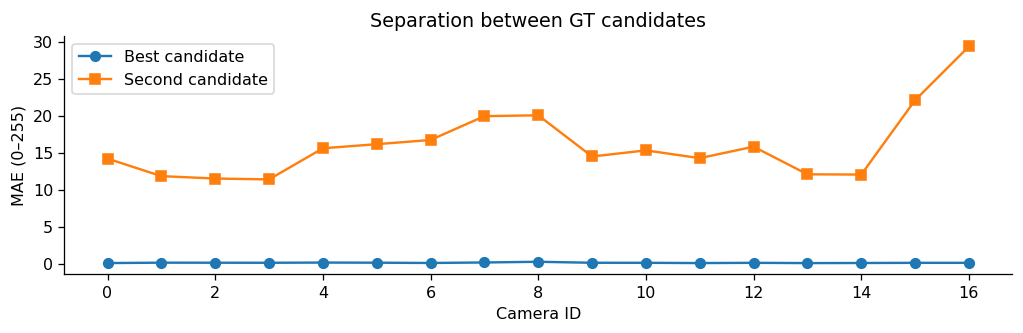

In [8]:
# Check matching images using the 17 x 17 x 2 recorded comparisons.
ver=czip(zGT,'verificacion_gt.csv',dtype={'imagen_esperada':str,'imagen_mas_parecida':str})
compar=czip(zGT,'comparaciones_todas.csv',dtype={'imagen_candidata':str})
ver_json=jzip(zGT,'resumen_verificacion.json')
assert len(compar)==17*17*2 and len(ver)==17
minimos=compar.sort_values('mae_rgb_0_255').drop_duplicates(['gt','imagen_candidata'])
mejores=minimos.sort_values('mae_rgb_0_255').drop_duplicates('gt')
check=ver.merge(mejores[['gt','imagen_candidata','fondo','mae_rgb_0_255']],on='gt',validate='one_to_one')
assert (check.imagen_esperada==check.imagen_candidata).all()
assert check.imagen_candidata.nunique()==17
assert (check.fondo=='negro').all()
assert np.allclose(check.mae_mejor,check.mae_rgb_0_255)
plan_name=next(n for n in zGT.namelist() if n.endswith('/plan.json'))
plan=jzip(zGT,plan_name)
assert all(plan['gt_sha256'][r.gt]==r.sha256_gt for r in ver.itertuples())
print('Expected matches:',len(check),'| Exact RGB matches:',int(ver.igualdad_exacta_esperada_negro.sum()))
print('Best MAE: minimum, mean, maximum:',ver.mae_mejor.agg(['min','mean','max']).to_dict())
print('Minimum MAE of the second candidate:',ver.mae_segunda_imagen.min())
display(ver[['gt','imagen_esperada','imagen_mas_parecida','mae_mejor','mae_segunda_imagen','ancho_gt','alto_gt']])
fig,ax=plt.subplots(figsize=(9,3)); ax.plot(ver.camara_id,ver.mae_mejor,'o-',label='Best candidate'); ax.plot(ver.camara_id,ver.mae_segunda_imagen,'s-',label='Second candidate'); ax.set(xlabel='Camera ID',ylabel='MAE (0–255)',title='Separation between GT candidates'); ax.legend(); plt.tight_layout(); plt.show()

**Interpretation:** 17/17 cameras were identified correctly, with no swapped references, a black background and a resolution of 406 × 405. The MAE results show a clear match, but the approximate image preparation did not produce identical pixels. All 17 hashes match the historical plan. The actual preparation includes resizing and masking; the exact cause of the pixel differences is not confirmed.

## III.2. Source code review and risk of data leakage in SDF
The attached source files were reviewed, not the remote repository. `trainer.py` visits each camera once per cycle. `readNerfSyntheticInfo` adds the test views to the training views if `--eval` is not used. The problematic path is different: `load_nerf_frames` also reads `transforms_test.json`, and the SDF configuration selects 72 views from the loaded set. This historical risk explains the common correction applied to A0 and A1. It is not possible to certify retrospectively the exact bytes of the reader used in October. The full origin of `env_gs.ply` and `points3d.ply` is also not yet known.

In [9]:
# Show actual source code excerpts with line numbers.
def fragmento(src, patron, antes=2, despues=12):
    lines=src.splitlines(); i=next(i for i,line in enumerate(lines) if patron in line)
    return '\n'.join(f'{j+1:4d}  {lines[j]}' for j in range(max(0,i-antes),min(len(lines),i+despues+1)))
trainer=(E/'trainer(1).py').read_text(encoding='utf-8-sig')
scene=(E/'__init__.py').read_text(encoding='utf-8-sig')
reader=(E/'dataset_readers.py').read_text(encoding='utf-8-sig')
sdf=tzip(zP,'transparentgs_trabajo/sdfproxy/models/dataset.py')
conf=tzip(zP,'transparentgs_trabajo/sdfproxy/confs/base.conf')
for label,src,pat in [('A0 sampler',trainer,'# Pick a random Camera'),('Order before shuffling',scene,'if scene_info.test_cameras:'),('Separation with --eval',reader,'def readNerfSyntheticInfo'),('SDF: files loaded',sdf,'def load_nerf_frames')]:
    print('\n'+label+'\n'+fragmento(src,pat,0,15))
print('SDF views:',re.search(r'views\s*=\s*(\d+)',conf).group(1))
assert all('eval=True' in tzip(zGT,n) for n in zGT.namelist() if n.endswith('cfg_args') and '/experimentos/' in n)
print('cfg_args of the five M runs: eval=True in the trainers.')


A0 sampler
 212          # Pick a random Camera
 213          if not viewpoint_stack:
 214              viewpoint_stack = scene.getTrainCameras().copy()
 215          viewpoint_cam = viewpoint_stack.pop(randint(0, len(viewpoint_stack)-1))
 216          
 217          render_pkg = gbuffer_pass(viewpoint_cam, gaussians, pipe, background)
 218          image, viewspace_point_tensor, visibility_filter, radii = render_pkg["render"], render_pkg["viewspace_points"], render_pkg["visibility_filter"], render_pkg["radii"]
 219          rend_dist = render_pkg["rend_dist"]
 220          rend_normal  = render_pkg['rend_normal']
 221          surf_normal = render_pkg['surf_normal']
 222          rend_alpha = render_pkg['rend_alpha']
 223          surf_points = render_pkg['surf_points']
 224          surf_depth = render_pkg['surf_depth']
 225          gt_image = viewpoint_cam.original_image.cuda()
 226          gt_mask = viewpoint_cam.gt_alpha_mask.cuda()
 227  

Order before shuffling
  58          

## IV.1. Designing A1 (step 5)
A0 selects each image with equal probability, without replacement within a cycle. In A1, the three groups are selected in random order without replacement. Within each group, a camera is selected without replacement until that group's list is exhausted. The number of iterations and the loss function remain the same. The expected share of selections for each group changes from $n_g/119$ to $1/3$. The relative probability of selecting an individual camera is $119/(3n_g)$. This is not the AIF360 label reweighing method; it is stratified sampling.

In [10]:
prep=jzip(zP,'preparacion_A1.json')
assert prep['estado']=='A1_PREPARADA_NO_EJECUTADA' and not prep['faltantes']
for p,h in prep['archivos_A1_sha256'].items(): assert sha_bytes(miembro(zP,p))==h
balance=pd.DataFrame({'n_train':conteos.train,'A0_proporcion_esperada':conteos.train/119,'A1_proporcion_objetivo':1/3,'factor_por_camara':119/(3*conteos.train)})
display(balance)
# Inspect the actual sampler without running its imports or training.
a1src=tzip(zP,'transparentgs_trabajo/trainer_auditoria_A1.py')
tree=ast.parse(a1src)
selector=next(n for n in tree.body if isinstance(n,ast.ClassDef) and n.name=='MuestreoAngularA1')
display(Code(ast.get_source_segment(a1src,selector),language='python'))

,n_train,A0_proporcion_esperada,A1_proporcion_objetivo,factor_por_camara
grupo,,,,
Bajo,34,0.285714,0.333333,1.166667
Medio,62,0.521008,0.333333,0.639785
Alto,23,0.193277,0.333333,1.724638


class MuestreoAngularA1:
    def __init__(self, dataset, cameras):
        import json, math
        from collections import Counter
        if not dataset.eval:
            raise RuntimeError("A1 requires --eval; test cameras must remain separate.")
        def name(path):
            return os.path.splitext(str(path).replace("\\", "/").rsplit("/", 1)[-1])[0]
        with open(os.path.join(dataset.source_path, "transforms_train.json"), encoding="utf-8-sig") as f:
            train = json.load(f)["frames"]
        with open(os.path.join(dataset.source_path, "transforms_test.json"), encoding="utf-8-sig") as f:
            test = json.load(f)["frames"]
        groups = {}
        for frame in train:
            n = name(frame["file_path"])
            if n in groups:
                raise RuntimeError("Duplicate training camera: " + n)
            col = [frame["transform_matrix"][i][2] for i in range(3)]
            norm = math.sqrt(sum(x*x for x in col))
            angle = math.degrees(math.asin(max(-1., min(1., col[2]/norm))))
            if not 0 <= angle <= 90:
                raise RuntimeError("Unexpected optical inclination")
            groups[n] = "Bajo" if angle < 20 else ("Medio" if angle < 40 else "Alto")
        test_names = [name(f["file_path"]) for f in test]
        if set(groups).intersection(test_names) or len(set(test_names)) != len(test_names):
            raise RuntimeError("Train/test overlap or duplicate test names")
        if len(test_names) != 17:
            raise RuntimeError("Expected the original 17 test cameras")
        self.members = {g: [] for g in ("Bajo", "Medio", "Alto")}
        self.group_by_name = groups
        self.name = name
        actual_names = [name(c.image_name) for c in cameras]
        if len(actual_names) != len(groups) or set(actual_names) != set(groups):
            raise RuntimeError("Training camera identities do not match transforms_train.json")
        for cam in cameras:
            self.members[groups[name(cam.image_name)]].append(cam)
        counts = {g: len(c) for g, c in self.members.items()}
        if counts != {"Bajo": 34, "Medio": 62, "Alto": 23}:
            raise RuntimeError("Unexpected A1 training counts: " + str(counts))
        self.group_stack = []
        self.camera_stacks = {g: [] for g in self.members}
        self.count_group = Counter({g: 0 for g in self.members})
        self.count_camera = Counter({n: 0 for n in groups})
        print("AUDITORIA_A1_GRUPOS: " + json.dumps(counts, sort_keys=True), flush=True)
    def next(self):
        # Random permutation of the three groups per cycle; random
        # permutation of cameras per group, refilled independently.
        if not self.group_stack:
            self.group_stack = list(self.members)
        g = self.group_stack.pop(randint(0, len(self.group_stack)-1))
        stack = self.camera_stacks[g]
        if not stack:
            stack.extend(self.members[g])
        cam = stack.pop(randint(0, len(stack)-1))
        self.count_group[g] += 1
        self.count_camera[self.name(cam.image_name)] += 1
        return cam
    def report(self, stage):
        import json
        print("AUDITORIA_A1_MUESTREO: " + json.dumps({
            "stage": int(stage), "selecciones_grupo": dict(self.count_group),
            "selecciones_camara": dict(self.count_camera),
            "selecciones_totales": sum(self.count_group.values())
        }, sort_keys=True), flush=True)

In [11]:
# Educational simulation of group scheduling; these are NOT training results.
# Reproduce sampling without replacement, using an independent RNG for illustration.
rng=np.random.default_rng(42)
miembros={g:train.loc[train.grupo==g,'imagen'].tolist() for g in GRUPOS}
gstack=[]; cstack={g:[] for g in GRUPOS}; sim_grupo=Counter(); sim_cam=Counter()
for _ in range(7000):
    if not gstack: gstack=list(GRUPOS)
    g=gstack.pop(int(rng.integers(len(gstack))))
    if not cstack[g]: cstack[g]=miembros[g].copy()
    c=cstack[g].pop(int(rng.integers(len(cstack[g]))))
    sim_grupo[g]+=1; sim_cam[c]+=1
assert len(sim_cam)==119 and max(sim_grupo.values())-min(sim_grupo.values())<=1
print('Sampler simulation (no GPU):',dict(sim_grupo))
print('The actual frequency is checked below in the pilot and final logs.')

Sampler simulation (no GPU): {'Bajo': 2334, 'Alto': 2333, 'Medio': 2333}
The actual frequency is checked below in the pilot and final logs.


## IV.2. Seed control, commands and pilot (step 6)
The previous launcher recognized only `trainer.py`. The function `safe_state()` can reset the random seeds to zero. A new `lanzador_semilla_auditoria.py` was created to recognize both trainers and set the requested seed after `safe_state`. Seed 42 was used for A0 and A1. This does not guarantee deterministic results from CUDA or every SDF operation.

The PowerShell commands used in the study are kept here for traceability. The included scripts are the original scripts that were sent or run. Some check hashes and local machine paths, and the continuation and evaluation scripts refer to existing run IDs. **Do not run them again just to study this notebook.**

In [12]:
# History of high-level commands. They are printed, NOT executed.
for archivo,flag in [('verificar_GT_TGS.py',''),('preparar_A1_TGS.py',''),('piloto_A0_A1_TGS.py','--piloto'),('continuar_A0_A1_TGS.py','--ejecutar'),('evaluar_A0_A1_TGS.py','--evaluar')]:
    print(f'python "$env:USERPROFILE\\Downloads\\{archivo}" "$([Environment]::GetFolderPath(\'Desktop\'))" {flag}'.strip())
print('\nThe five control scripts are included in evidencias/.')
print('New launcher excerpt:')
launcher=tzip(zPi,'Reproducibilidad_TransparentGS/07_Laboratorio/lanzador_semilla_auditoria.py')
display(Code(launcher,language='python'))

python "$env:USERPROFILE\Downloads\verificar_GT_TGS.py" "$([Environment]::GetFolderPath('Desktop'))"
python "$env:USERPROFILE\Downloads\preparar_A1_TGS.py" "$([Environment]::GetFolderPath('Desktop'))"
python "$env:USERPROFILE\Downloads\piloto_A0_A1_TGS.py" "$([Environment]::GetFolderPath('Desktop'))" --piloto
python "$env:USERPROFILE\Downloads\continuar_A0_A1_TGS.py" "$([Environment]::GetFolderPath('Desktop'))" --ejecutar
python "$env:USERPROFILE\Downloads\evaluar_A0_A1_TGS.py" "$([Environment]::GetFolderPath('Desktop'))" --evaluar

The five control scripts are included in evidencias/.
New launcher excerpt:


# -*- coding: utf-8 -*-
"""Lanza un script oficial desde su repositorio aplicando semillas al proceso hijo.

En trainer.py los autores llaman safe_state() que normalmente reinicia RNG.
Este lanzador intercepta esa llamada y aplica la semilla escogida DESPUÉS.
Se requiere comprobar experimentalmente su efectividad en cada etapa antes de
considerar los experimentos multi-seed como evidencia científica.
"""
from __future__ import annotations
import argparse
import random
import runpy
import sys
from pathlib import Path


def fijar_semilla(seed: int) -> None:
    import numpy as np
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def main() -> int:
    p = argparse.ArgumentParser(description="Lanzador de semillas reproducibles (experimental)")
    p.add_argument('--seed',required=True,type=int)
    p.add_argument('--script',required=True)
    args, rest = p.parse_known_args()
    script = Path(args.script).resolve()
    if not script.is_file():
        raise FileNotFoundError(script)
    if args.seed < 0 or args.seed >= 2**32:
        raise ValueError('Semilla debe estar entre 0 y 2^32-1')
    # La ruta del repositorio debe estar en sys.path para importaciones locales.
    sys.path.insert(0, str(script.parent))
    fijar_semilla(args.seed)
    if script.name in ('trainer.py', 'trainer_auditoria_A1.py'):
        import utils.general_utils as g
        original_safe_state = g.safe_state
        def safe_state_controlado(silent):
            original_safe_state(silent)
            fijar_semilla(args.seed)
            print('[LAB] Semilla aplicada después de safe_state:',args.seed,flush=True)
        g.safe_state = safe_state_controlado
    else:
        print('[LAB] Semilla previa al inicio del script:',args.seed,flush=True)
    sys.argv = [str(script), *rest]
    runpy.run_path(str(script),run_name='__main__')
    return 0


if __name__=='__main__':
    raise SystemExit(main())

In [13]:
# The pilot manifest records a parsing error, not a training error.
piloto=jzip(zPi,'piloto.json')
print('Pilot manifest status:',piloto['estado'],'| error:',piloto.get('error'))
pilotos=[]
for v in VARIANTES:
    a=jzip(zPi,f'{v}/logs/inicial.json'); log=tzip(zPi,f'{v}/logs/inicial.log')
    assert a['returncode']==0 and 'Training complete' in log and all(a['rutas_esperadas'].values())
    assert a['seed_solicitada']==42 and '--eval' in a['comando']
    pilotos.append({'variante':v,'segundos':a['duracion_s'],'returncode':a['returncode'],'semilla':a['seed_solicitada'],'Outputs present (record)':all(a['rutas_esperadas'].values())})
    print(v,'Recorded command:',a['comando'])
display(pd.DataFrame(pilotos))
# JSONDecoder.raw_decode recovers the object even if the logger adds a timestamp at the end.
def extraer_muestreo(log):
    marker='AUDITORIA_A1_MUESTREO:'
    line=[line for line in log.splitlines() if marker in line][-1]
    return json.JSONDecoder().raw_decode(line.split(marker,1)[1].strip())[0]
muestreo_inicial=extraer_muestreo(tzip(zPi,'A1/logs/inicial.log'))
assert muestreo_inicial['selecciones_totales']==7000
assert set(muestreo_inicial['selecciones_camara'])==set(train.imagen)
assert sum(muestreo_inicial['selecciones_grupo'].values())==7000
print('A1 initial stage, actual count:',muestreo_inicial['selecciones_grupo'])

Pilot manifest status: ERROR | error: JSONDecodeError('Extra data: line 1 column 1584 (char 1583)')
A0 Recorded command: ['C:\\Users\\eafa1\\anaconda3\\envs\\transparentgs\\python.exe', 'D:\\Doctorado_DeepTech\\TransparentGS\\Reproducibilidad_TransparentGS\\07_Laboratorio\\lanzador_semilla_auditoria.py', '--seed', '42', '--script', 'D:\\Doctorado_DeepTech\\TransparentGS\\transparentgs_trabajo\\trainer.py', '-s', 'D:\\Doctorado_DeepTech\\TransparentGS\\experimentos\\audit_clean_A0_seed_42_20261126_101740_848793\\datos\\apple20', '-m', 'D:\\Doctorado_DeepTech\\TransparentGS\\experimentos\\audit_clean_A0_seed_42_20261126_101740_848793\\modelo', '--eval', '--stage', '1', '--iterations', '7000', '-r', '2', '--save_iterations', '7000']
A1 Recorded command: ['C:\\Users\\eafa1\\anaconda3\\envs\\transparentgs\\python.exe', 'D:\\Doctorado_DeepTech\\TransparentGS\\Reproducibilidad_TransparentGS\\07_Laboratorio\\lanzador_semilla_auditoria.py', '--seed', '42', '--script', 'D:\\Doctorado_DeepTech\\T

,variante,segundos,returncode,semilla,Outputs present (record)
0,A0,102.578000,0,42,True
1,A1,97.750000,0,42,True


A1 initial stage, actual count: {'Alto': 2333, 'Bajo': 2333, 'Medio': 2334}


The pilot finished with a return code of zero for both configurations. The `JSONDecodeError` in the manifest was caused by a timestamp at the end of the log. The JSON was recovered without editing the log or repeating the initial stage. PLY files are not included; their existence was documented by the local controller.

## IV.3. Complete reconstruction and SDF isolation
Both pilot runs were continued without restarting stage 1. The stages were: initial training (7,000 iterations), mesh generation, GaussProbe, SDF refinement (20,000 iterations), and final training (7,000 iterations). The corrected controllers create separate SDF input data with 119 training images and masks and no test views. The internal selection of 72 views remains active. The manifests confirm the declared inputs and the hash checks performed locally, but cannot certify all bytes of the missing PLY/EXR files. SDF used mask supervision because `screen_point` was missing.

A0 SDF train: 119 test: 0 Image/mask files: 238
A1 SDF train: 119 test: 0 Image/mask files: 238


,variante,etapa,segundos,retorno,pico_gpu0_total_mib
0,A0,inicial,102.578000,0,NaN
1,A0,malla,18.750000,0,2047.000000
2,A0,gaussprobe,23.297000,0,5771.000000
3,A0,sdf,6338.000000,0,12116.000000
4,A0,final,2853.250000,0,6287.000000
5,A1,inicial,97.750000,0,NaN
6,A1,malla,19.782000,0,1599.000000
7,A1,gaussprobe,24.391000,0,5763.000000
8,A1,sdf,17783.453000,0,5786.000000
9,A1,final,2831.640000,0,6476.000000


,A0 expected (%),A1 initial measured (%),A1 final measured (%)
Bajo,28.571429,33.328571,33.328571
Medio,52.100840,33.342857,33.342857
Alto,19.327731,33.328571,33.328571


A1 final: {'Alto': 2333, 'Bajo': 2333, 'Medio': 2334}


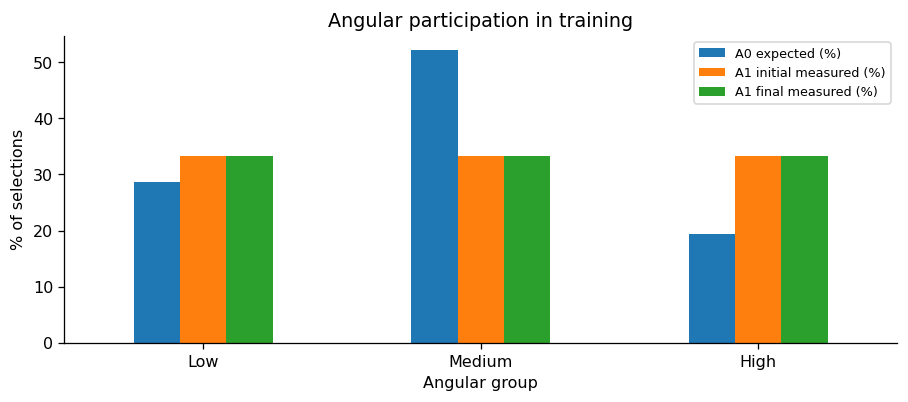

In [14]:
continuacion=jzip(zC,'continuacion.json')
assert continuacion['estado']=='COMPLETO_SIN_EVALUACION' and continuacion['semilla']==42
assert continuacion['entrada_identica'] and continuacion['sha_fuentes_sin_cambios']
registros=[]
for v in VARIANTES:
    sdfman=jzip(zC,f'{v}/datos_sdf/manifest_SDF_train.json')
    assert sdfman['train_count']==119 and sdfman['test_count']==0
    assert set(sdfman['train_names'])==set(train.imagen)
    assert set(sdfman['test_names_excluded'])==set(test.imagen)
    assert sdfman['train_json_sha256']==sha_bytes((E/'transforms_train.json').read_bytes())
    assert miembro(zC,f'{v}/modelo/cameras.json')==(E/'cameras.json').read_bytes()
    print(v,'SDF train:',sdfman['train_count'],'test:',sdfman['test_count'],'Image/mask files:',sdfman['files'])
    for etapa in ETAPAS:
        meta=jzip(zC,f'{v}/logs/{etapa}.json'); dato=continuacion['etapas'][v][etapa]
        assert meta['returncode']==0 and meta['seed_solicitada']==42 and all(meta['rutas_esperadas'].values())
        registros.append({'variante':v,'etapa':etapa,'segundos':dato['duracion_s'],'retorno':meta['returncode'],'pico_gpu0_total_mib':dato.get('pico_gpu0_total_mib',np.nan),'comando':meta['comando']})
rec=pd.DataFrame(registros)
display(rec.drop(columns='comando'))
muestreo_final=extraer_muestreo(tzip(zC,'A1/logs/final.log'))
assert muestreo_final['selecciones_totales']==7000 and set(muestreo_final['selecciones_camara'])==set(train.imagen)
assert sum(muestreo_final['selecciones_grupo'].values())==7000
for m in [muestreo_inicial,muestreo_final]:
    assert max(m['selecciones_grupo'].values())-min(m['selecciones_grupo'].values())<=1
    assert sum(m['selecciones_camara'].values())==7000
reparto=pd.DataFrame({'A0 expected (%)':balance.A0_proporcion_esperada*100,'A1 initial measured (%)':pd.Series(muestreo_inicial['selecciones_grupo'])/70,'A1 final measured (%)':pd.Series(muestreo_final['selecciones_grupo'])/70}).reindex(GRUPOS)
display(reparto); print('A1 final:',muestreo_final['selecciones_grupo'])
ax=reparto.plot.bar(figsize=(8,3.6),rot=0); ax.set(ylabel='% of selections',title='Angular participation in training'); ax.set_xlabel('Angular group'); ax.set_xticks(range(3), ['Low','Medium','High']); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [15]:
# Full record of the commands for each stage (text only, no execution).
for r in rec.itertuples():
    print(f'[{r.variante} / {r.etapa}]')
    print(' '.join('"'+str(p)+'"' if ' ' in str(p) else str(p) for p in r.comando))

[A0 / inicial]
C:\Users\eafa1\anaconda3\envs\transparentgs\python.exe D:\Doctorado_DeepTech\TransparentGS\Reproducibilidad_TransparentGS\07_Laboratorio\lanzador_semilla_auditoria.py --seed 42 --script D:\Doctorado_DeepTech\TransparentGS\transparentgs_trabajo\trainer.py -s D:\Doctorado_DeepTech\TransparentGS\experimentos\audit_clean_A0_seed_42_20261126_101740_848793\datos\apple20 -m D:\Doctorado_DeepTech\TransparentGS\experimentos\audit_clean_A0_seed_42_20261126_101740_848793\modelo --eval --stage 1 --iterations 7000 -r 2 --save_iterations 7000
[A0 / malla]
C:\Users\eafa1\anaconda3\envs\transparentgs\python.exe D:\Doctorado_DeepTech\TransparentGS\Reproducibilidad_TransparentGS\07_Laboratorio\lanzador_semilla_auditoria.py --seed 42 --script D:\Doctorado_DeepTech\TransparentGS\transparentgs_trabajo\coarsemesh_gs.py -s D:\Doctorado_DeepTech\TransparentGS\experimentos\audit_clean_A0_seed_42_20261126_101740_848793\datos\apple20 -m D:\Doctorado_DeepTech\TransparentGS\experimentos\audit_clean_

**Result of the intervention:** balanced selection frequencies were implemented and measured in both stages of the A1 trainer. This does not yet demonstrate an improvement in perceptual quality. The SDF and seed-control corrections are common to both configurations. For this reason, the difference between M and A0 is not attributed to A1.

## V.1. Paired evaluation protocol (step 7)
Both models use the same GT images: 17 cameras, 406 × 405 resolution, black background, fixed IOR of 1.45, 8 probes, 5 query iterations, pinhole camera and render mode. The adapted evaluator uses the final mesh and probes. It is not identical to the training shading function and is not a verified reproduction of the metrics in the original paper.

PSNR: $10\log_{10}(1/\mathrm{MSE})$ using RGB values in [0,1]. SSIM: structural similarity. LPIPS-Alex: perceptual distance (lower is better). PSNR and SSIM are recalculated from the PNG files; LPIPS is read from the original CSV. Recalculating LPIPS would require its weights and software environment; it is not simulated.

In [16]:
evman=jzip(zE,'evaluacion.json')
assert evman['estado']=='COMPLETO' and evman['semilla_entrenamiento_solicitada']==42 and evman['semilla_evaluacion']==2026
assert evman['modelos_y_fuentes_verificados_sin_cambios']
print('Actual protocol:',evman['protocolo'])
for v in VARIANTES: assert miembro(zE,f'{v}/cameras.json')==(E/'cameras.json').read_bytes()
ref_by_id={r['id']:r for r in evman['vistas']}
render_by_key={(r['variante'],r['camara_id']):r for r in evman['renderizados']}
assert len(ref_by_id)==17 and len(render_by_key)==34
for i,r in ref_by_id.items():
    assert r['name']==test.loc[i,'imagen'] and r['grupo']==test.loc[i,'grupo']
    assert np.isclose(r['tilt_deg'],test.loc[i,'angulo'],atol=1e-9)
    assert sha_bytes(miembro(zE,'referencias/'+r['gt']))==r['sha256']==plan['gt_sha256'][r['gt']]
print('17 references and their historical hashes verified.')

def imagen_rgb(z,n):
    with Image.open(io.BytesIO(miembro(z,n))) as im:
        return np.asarray(im.convert('RGB'),dtype=np.float64)/255.0

# Rebuild the table of 34 results using the actual CSV and PNG files.
final=[]
for v in VARIANTES:
    df=czip(zE,f'{v}/metricas/metricas_por_vista.csv'); pares=czip(zE,f'{v}/pares_test_optico.csv')
    df['id']=comprobar_pares(df,pares)
    for row in df.itertuples():
        i=row.id; ref=ref_by_id[i]; rend=render_by_key[(v,i)]
        gtname='referencias/'+ref['gt']; rname=f'{v}/'+basename(row.render)
        assert rend['imagen']==ref['name'] and rend['sha256_gt']==ref['sha256']
        assert sha_bytes(miembro(zE,rname))==rend['sha256_render']
        gt=imagen_rgb(zE,gtname); pred=imagen_rgb(zE,rname)
        assert gt.shape==pred.shape==(405,406,3)
        ps=peak_signal_noise_ratio(gt,pred,data_range=1)
        ss=structural_similarity(gt,pred,channel_axis=-1,data_range=1)
        final.append({'variante':v,'id':i,'imagen':ref['name'],'grupo':ref['grupo'],'angulo':test.loc[i,'angulo'],
            'psnr':row.psnr,'ssim':row.ssim,'lpips_alex':row.lpips_alex,'psnr_recalculado':ps,'ssim_recalculado':ss,'segundos_render':rend['segundos']})
    resumen=jzip(zE,f'{v}/metricas/resumen_metricas.json')
    for m in METRICAS:
        assert np.isclose(df[m].mean(),resumen['resultados'][m]['media'],atol=1e-12,rtol=0)
        assert np.isclose(df[m].std(ddof=1),resumen['resultados'][m]['desviacion_estandar_muestral'],atol=1e-12,rtol=0)
F=pd.DataFrame(final)
for m in ['psnr','ssim']:
    maxdiff=(F[m]-F[m+'_recalculado']).abs().max()
    print('Maximum difference',m,':',f'{maxdiff:.3g}')
    assert maxdiff<1e-5
print('34 renders and 17 GT images verified. LPIPS is read from the original evaluator.')
display(F[['variante','id','imagen','grupo']+METRICAS])

Actual protocol: {'resolucion': [406, 405], 'ior': 1.45, 'fondo': 'black', 'num_probes': 8, 'query_iters': 5, 'meshproxy_pitch': 0.01, 'cam_mode': 'pinhole', 'mode': 'render'}


17 references and their historical hashes verified.


Maximum difference psnr : 3.67e-07
Maximum difference ssim : 4.76e-07
34 renders and 17 GT images verified. LPIPS is read from the original evaluator.


,variante,id,imagen,grupo,psnr,ssim,lpips_alex
0,A0,0,0000,Alto,21.015413,0.857553,0.117663
1,A0,1,0008,Bajo,20.838615,0.849053,0.163898
2,A0,2,0016,Medio,20.894856,0.836663,0.147176
3,A0,3,0024,Alto,21.881345,0.845155,0.157021
4,A0,4,0032,Bajo,21.129313,0.853487,0.162314
5,A0,5,0040,Medio,19.247341,0.832302,0.174628
6,A0,6,0048,Alto,20.543420,0.823368,0.165404
7,A0,7,0056,Bajo,19.077107,0.826483,0.232458
8,A0,8,0064,Medio,19.441983,0.775962,0.273498
9,A0,9,0072,Medio,20.643606,0.848385,0.160514


## V.2. Visual comparison of the real images
All 17 views are shown, with the same reference images for A0 and A1. The visual appearance of a reconstruction does not replace a geometric measurement. The renders are read directly from the evaluation ZIP without changing the PNG files.

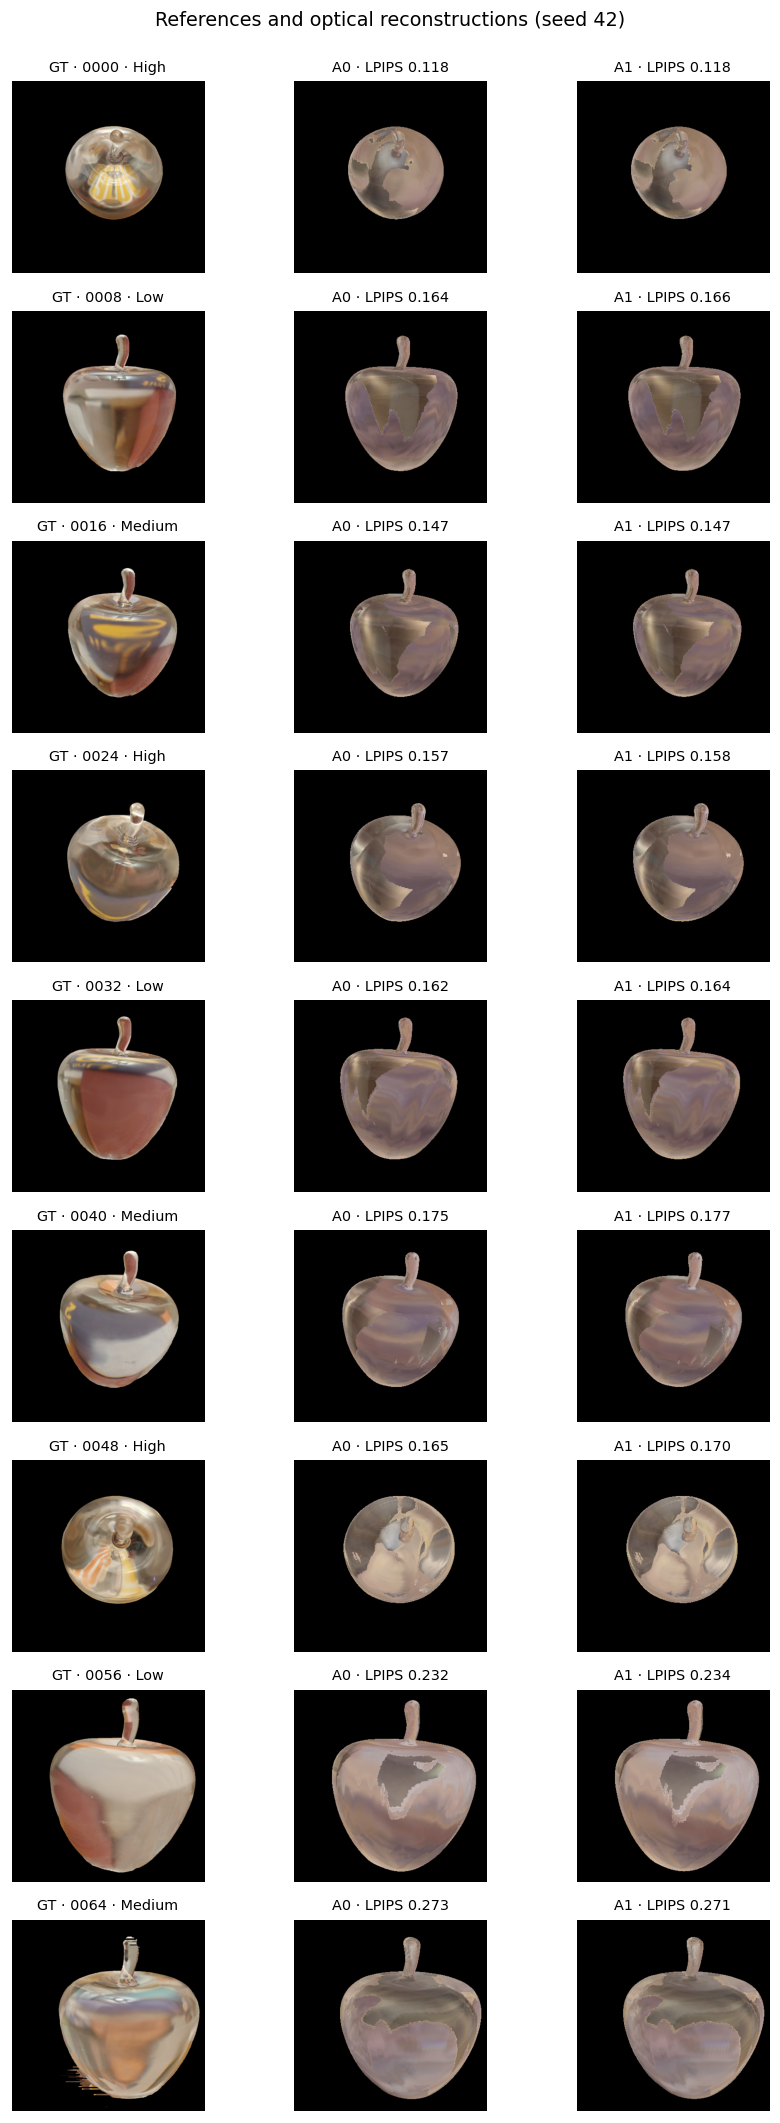

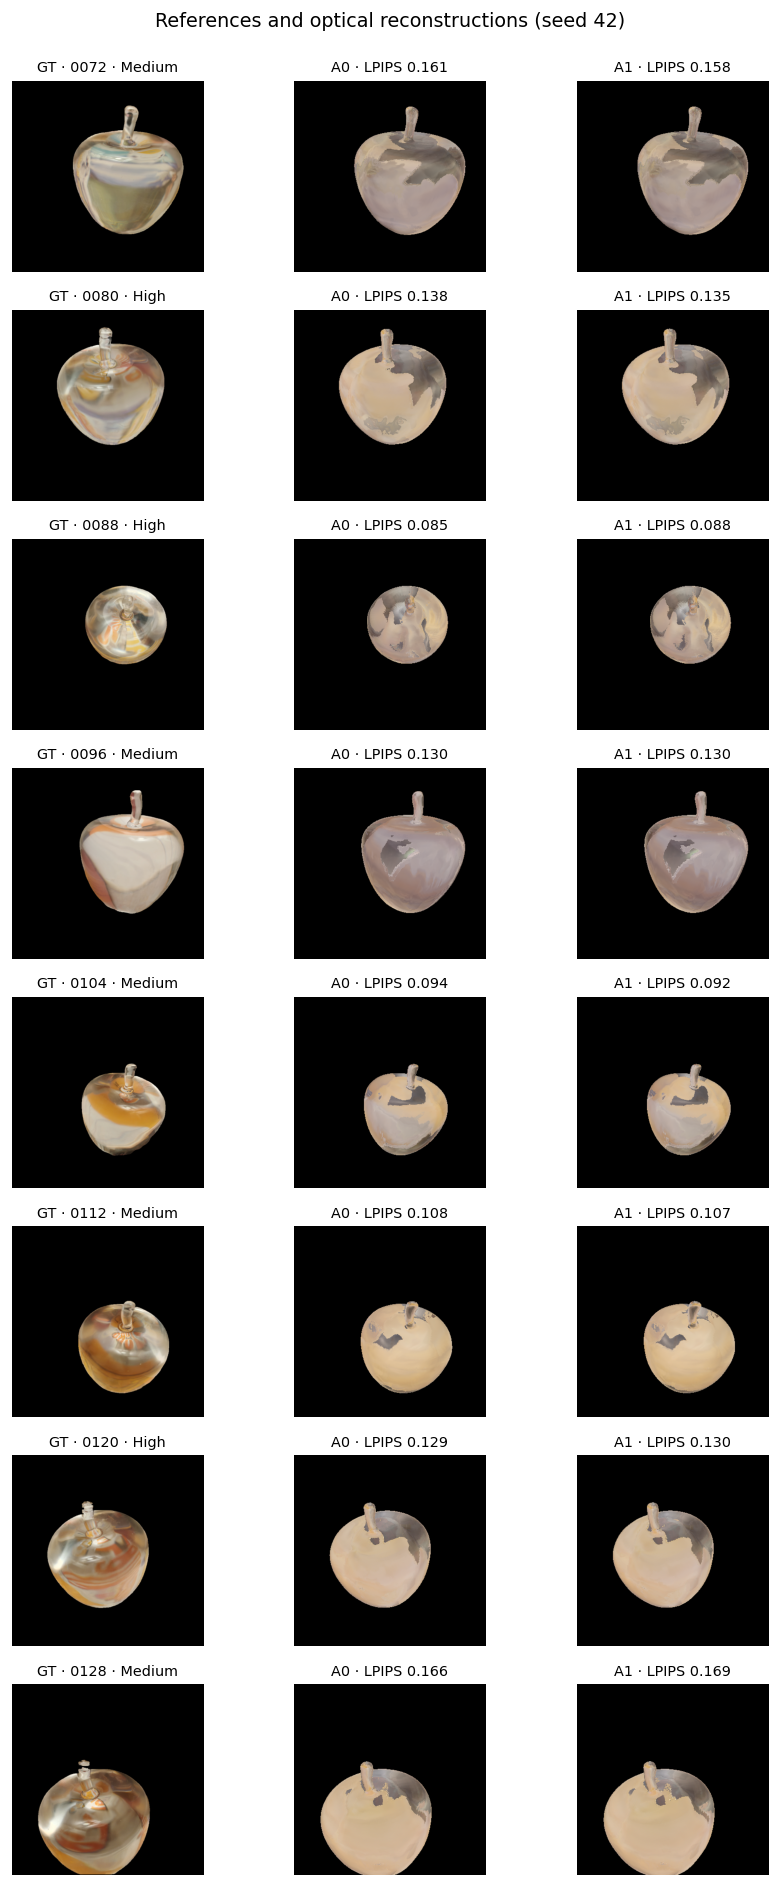

In [17]:
# Two figures for readability (17 rows in total).
for ids in [list(range(9)),list(range(9,17))]:
    fig,axes=plt.subplots(len(ids),3,figsize=(8,2.05*len(ids)))
    for j,i in enumerate(ids):
        ref=ref_by_id[i]
        for k,(title,n) in enumerate([('GT','referencias/'+ref['gt']),('A0',f'A0/optico_test_{i:02d}.png'),('A1',f'A1/optico_test_{i:02d}.png')]):
            ax=axes[j,k]; ax.imshow(imagen_rgb(zE,n)); ax.axis('off')
            if k==0: ax.set_title(f'{title} · {ref["name"]} · '+{'Bajo':'Low','Medio':'Medium','Alto':'High'}[ref['grupo']],fontsize=9)
            else:
                x=F[(F.variante==title)&(F.id==i)].iloc[0]
                ax.set_title(f'{title} · LPIPS {x.lpips_alex:.3f}',fontsize=9)
    fig.suptitle('References and optical reconstructions (seed 42)',y=.998,fontsize=12)
    plt.tight_layout(); plt.show()

## V.3. Overall results, group results and gaps (step 8)
Mean values are calculated across all 17 views and for each group. The overall SD for each configuration is measured across views, not across training runs. For each metric:
$$B_m=\max_g\overline{m}_g-\min_g\overline{m}_g,\quad \Delta B_m=B_{m,A1}-B_{m,A0}.$$
A smaller gap may result from making the previously best group worse. The three group means and the worst group are therefore analyzed, not just the overall gap.

psnr              ssim          lpips_alex         
              mean      std     mean      std       mean      std
variante                                                         
A0       20.707273 1.410627 0.853353 0.032013   0.153177 0.046599
A1       20.636016 1.383186 0.852136 0.032251   0.153818 0.046650

psnr     ssim  lpips_alex
variante grupo                               
A0       Alto  21.634604 0.858771    0.131951
         Bajo  20.348345 0.843008    0.186223
         Medio 20.146373 0.853170    0.156705
A1       Alto  21.525165 0.857108    0.133110
         Bajo  20.230324 0.840119    0.188322
         Medio 20.121289 0.852914    0.156410

variante,Antes_A0,Despues_A1,delta_A1_A0
psnr,20.707273,20.636016,-0.071257
ssim,0.853353,0.852136,-0.001217
lpips_alex,0.153177,0.153818,0.000640


variante,A0,A1,delta_A1_A0
psnr,1.488230,1.403876,-0.084355
ssim,0.015763,0.016989,0.001226
lpips_alex,0.054272,0.055212,0.000939


A0 psnr worst group: Medio mean: 20.146373
A1 psnr worst group: Medio mean: 20.121289
A0 ssim worst group: Bajo mean: 0.843008
A1 ssim worst group: Bajo mean: 0.840119
A0 lpips_alex worst group: Bajo mean: 0.186223
A1 lpips_alex worst group: Bajo mean: 0.188322


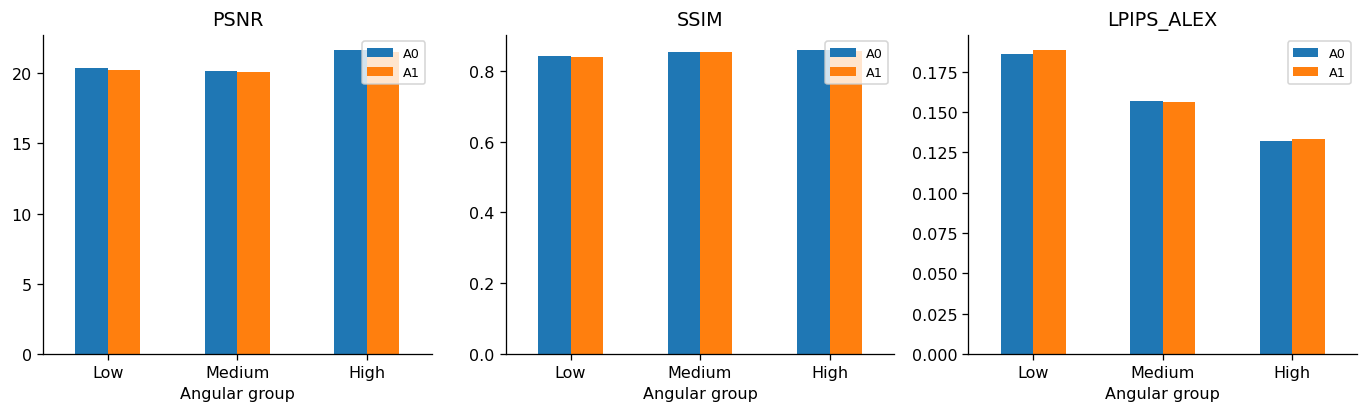

In [18]:
G=F.groupby('variante')[METRICAS].agg(['mean','std'])
medias=F.groupby('variante')[METRICAS].mean()
porgrupo=F.groupby(['variante','grupo'])[METRICAS].mean()
brechas=porgrupo.groupby('variante').max()-porgrupo.groupby('variante').min()
display(G); display(porgrupo)
comparacion=medias.T.rename(columns={'A0':'Antes_A0','A1':'Despues_A1'})
comparacion['delta_A1_A0']=comparacion.Despues_A1-comparacion.Antes_A0
display(comparacion)
B=brechas.T.copy(); B['delta_A1_A0']=B.A1-B.A0; display(B)
for m in METRICAS:
    for v in VARIANTES:
        a=porgrupo.loc[v,m]; peor=a.idxmax() if m=='lpips_alex' else a.idxmin()
        print(v,m,'worst group:',peor,'mean:',round(a[peor],6))
# Check against the derived CSV files saved at the end of the audit.
ref=leer_csv('apple20_A0_A1_grupos_v16.csv').set_index(['variante','grupo'])
assert np.allclose(porgrupo.sort_index(),ref.loc[porgrupo.sort_index().index,METRICAS],atol=1e-12,rtol=0)
fig,axes=plt.subplots(1,3,figsize=(12,3.7))
for m,ax in zip(METRICAS,axes):
    tabla=porgrupo[m].unstack('variante').reindex(GRUPOS)
    tabla.plot.bar(ax=ax,rot=0,title=m.upper()); ax.set_xlabel('Angular group'); ax.set_xticks(range(3), ['Low','Medium','High']); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

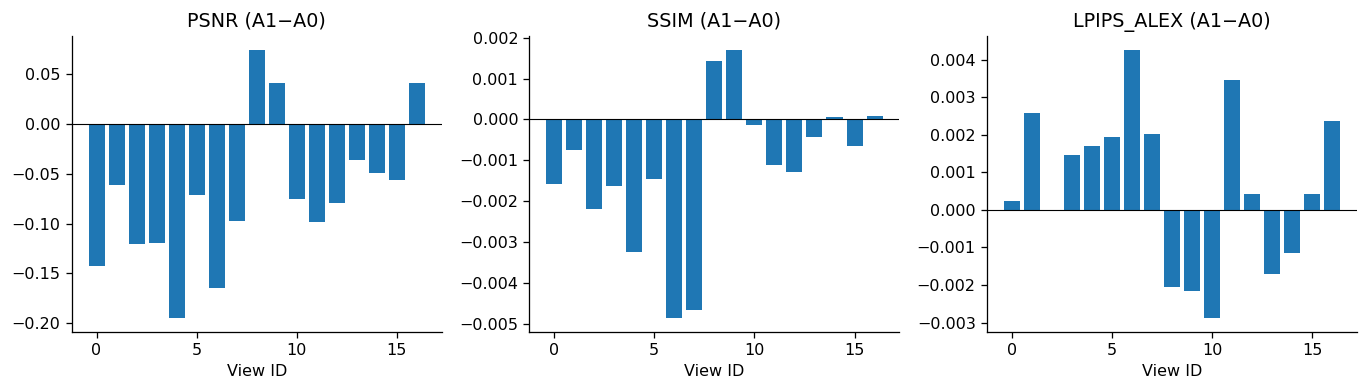

,imagen,grupo,psnr,ssim,lpips_alex
id,,,,,
0,0000,Alto,-0.142867,-0.001576,0.000242
1,0008,Bajo,-0.061788,-0.000757,0.002575
2,0016,Medio,-0.120097,-0.002189,-0.000013
3,0024,Alto,-0.119852,-0.001635,0.001463
4,0032,Bajo,-0.195127,-0.003248,0.001697
5,0040,Medio,-0.071201,-0.001448,0.001926
6,0048,Alto,-0.164368,-0.004865,0.004266
7,0056,Bajo,-0.097148,-0.004663,0.002024
8,0064,Medio,0.074276,0.001440,-0.002058


In [19]:
# Paired difference for each view; cameras are not treated as independent training observations.
a=F.query("variante=='A0'").set_index('id').sort_index()
b=F.query("variante=='A1'").set_index('id').sort_index()
assert a.index.equals(b.index) and a.imagen.equals(b.imagen) and a.grupo.equals(b.grupo)
delta=b[METRICAS]-a[METRICAS]; delta['grupo']=a.grupo; delta['imagen']=a.imagen
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for m,ax in zip(METRICAS,axes):
    ax.bar(delta.index,delta[m]); ax.axhline(0,color='black',lw=.7); ax.set(title=m.upper()+' (A1−A0)',xlabel='View ID')
plt.tight_layout(); plt.show()
display(delta[['imagen','grupo']+METRICAS])

**Interpretation of the new experiment (one seed):**
- Overall PSNR falls from 20.7073 to 20.6360 dB. Its gap decreases from 1.48823 to 1.40388 dB because the best group becomes worse by a larger amount; no group improves in PSNR.
- Overall SSIM falls from 0.85335 to 0.85214, and its gap increases from 0.01576 to 0.01699.
- Overall LPIPS increases from 0.15318 to 0.15382 (worse). LPIPS for low angles increases from 0.186223 to 0.188322, and the low–high gap increases from 0.054272 to 0.055212.

No perceptual mitigation is demonstrated. The negative result does not invalidate the audit: it separates the technical success of balancing the samples from its effect on quality.

## V.4. Uncertainty: paired and stratified bootstrap
The A1−A0 differences for the same cameras are resampled with replacement within each group (3/8/6), keeping the paired measurements together. The analysis uses 10,000 replicates, `default_rng(2026)`, and the 2.5th/97.5th percentiles. The main contrast is the change in the low–high LPIPS gap. For the overall metrics, the resampled means are weighted by the actual number of views. Nearby views may be dependent, and three low-angle cameras are a small sample. This is a descriptive sensitivity analysis for the pair of models, not uncertainty across training runs or ten data splits.

Change in low−high LPIPS gap: 0.000939408
Recalculated percentile interval: [-0.00089759  0.00287236]
Interval preserved in V16: [-0.0008975913127263293, 0.0028723627328872724]


,metrica,delta_global,p2.5,p97.5
0,psnr,-0.071257,-0.096646,-0.045530
1,ssim,-0.001217,-0.001911,-0.000574
2,lpips_alex,0.000640,-0.000207,0.001497


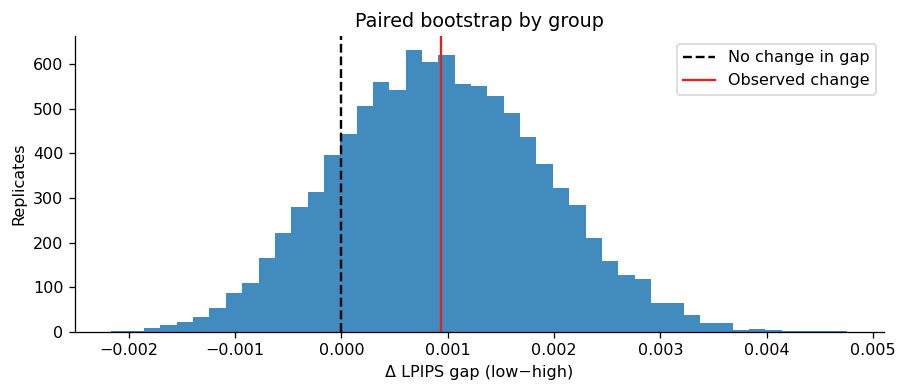

In [20]:
N_BOOT=10000; rng=np.random.default_rng(2026)
# Resample each full row together (keeping all three metrics).
boot={}
for g in GRUPOS:
    arr=delta.loc[delta.grupo==g,METRICAS].to_numpy()
    ix=rng.integers(0,len(arr),size=(N_BOOT,len(arr)))
    boot[g]=arr[ix].mean(axis=1)
contraste=boot['Bajo'][:,2]-boot['Alto'][:,2]
boot_global=sum(boot[g]*int(conteos.loc[g,'test']) for g in GRUPOS)/17
puntual=delta.loc[delta.grupo=='Bajo','lpips_alex'].mean()-delta.loc[delta.grupo=='Alto','lpips_alex'].mean()
limites=np.percentile(contraste,[2.5,97.5])
refboot=leer_json('apple20_A0_A1_incertidumbre_v16.json')
print('Change in low−high LPIPS gap:',f'{puntual:.9f}')
print('Recalculated percentile interval:',limites)
print('Interval preserved in V16:',refboot['intervalo_percentil'])
assert np.isclose(puntual,refboot['delta_brecha_lpips_bajo_alto'],atol=1e-12,rtol=0)
# Different RNG call orders may slightly change the Monte Carlo percentiles.
res_boot=pd.DataFrame({'metrica':METRICAS,'delta_global':delta[METRICAS].mean().values,'p2.5':np.percentile(boot_global,2.5,axis=0),'p97.5':np.percentile(boot_global,97.5,axis=0)})
display(res_boot)
fig,ax=plt.subplots(figsize=(8,3.5)); ax.hist(contraste,bins=45,alpha=.85); ax.axvline(0,color='black',ls='--',label='No change in gap'); ax.axvline(puntual,color='tab:red',label='Observed change'); ax.set(xlabel='Δ LPIPS gap (low−high)',ylabel='Replicates',title='Paired bootstrap by group'); ax.legend(); plt.tight_layout(); plt.show()

The interval in V16 is approximately [−0.000898, 0.002872], and includes zero. The recalculation uses the same design. If the percentiles differ because of the order in which the random number generator is used, both results are retained and the difference is reported. There is no conclusive evidence of a reduction in the perceptual gap. Lack of evidence does not prove equivalence.

## VI.1. Computational cost (step 9)
The elapsed times for each stage are recovered and checked against `nvidia-smi` telemetry. These times do not represent exclusive GPU processing time. Total GPU0 memory was sampled approximately every two seconds. It is not exclusive to TransparentGS and does not include the initial stage. The recorded maxima may miss brief peaks. Based on only one pair of runs, the cost of A1 cannot be attributed directly to the sampling method.

variante,A0,A1
etapa,,
inicial,102.578000,97.750000
malla,18.750000,19.782000
gaussprobe,23.297000,24.391000
sdf,6338.000000,17783.453000
final,2853.250000,2831.640000


,pipeline_s,pipeline_h,GPU0_pico_GiB_sin_inicial,render_s
variante,,,,
A0,9335.875000,2.593299,11.832031,314.937000
A1,20757.016000,5.765838,6.324219,329.218000


A1/A0 time ratio: 2.2233605312838916


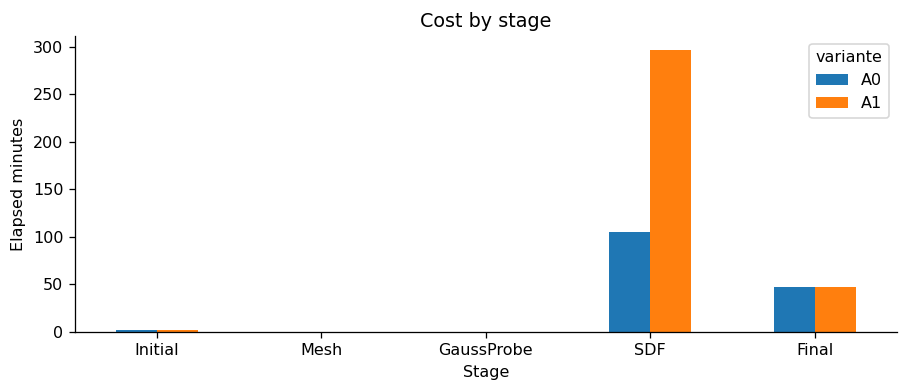

In [21]:
tele=czip(zC,'telemetria_gpu.csv')
for r in rec.dropna(subset=['pico_gpu0_total_mib']).itertuples():
    t=tele[(tele.variante==r.variante)&(tele.etapa==r.etapa)]
    assert np.isclose(t.gpu0_total_mib.max(),r.pico_gpu0_total_mib)
    assert len(t)==continuacion['etapas'][r.variante][r.etapa]['n_muestras']
tiempos=rec.pivot(index='etapa',columns='variante',values='segundos').reindex(ETAPAS)
display(tiempos)
costos=pd.DataFrame({'pipeline_s':tiempos.sum(),'pipeline_h':tiempos.sum()/3600,'GPU0_pico_GiB_sin_inicial':tele.groupby('variante').gpu0_total_mib.max()/1024,'render_s':F.groupby('variante').segundos_render.sum()})
display(costos)
print('A1/A0 time ratio:',costos.loc['A1','pipeline_s']/costos.loc['A0','pipeline_s'])
fig,ax=plt.subplots(figsize=(8,3.5)); (tiempos/60).plot.bar(ax=ax,rot=0); ax.set(ylabel='Elapsed minutes',title='Cost by stage',xlabel='Stage'); ax.set_xticks(range(5), ['Initial','Mesh','GaussProbe','SDF','Final']); plt.tight_layout(); plt.show()

## VI.2. Conclusions and recommendations (step 10)
**Answer to the research question:** the historical analysis showed a persistent angular gap in LPIPS. In the new comparison, camera balancing was achieved (2,333, 2,334 and 2,333 selections in the final stage), but it did not reduce the perceptual gap. The PSNR gap decreased because the best group became worse; an overall improvement was not demonstrated. A1 should not be adopted as a validated improvement.

The complete A1 pipeline took about 5 h 46 min, compared with 2 h 35 min for A0. Most of the time difference occurred in SDF. The maximum observed memory was lower in A1, but the result does not prove consistent memory savings.

### Relation to the assignment (Session 12 slides 45, 49 and 50)
| Requirement | Status |
|---|---|
| Dataset, groups and outcome | Documented; adapted to visual quality, not a protected attribute |
| Initial audit and metrics | Completed; exploratory M and new A0 |
| One justified intervention | A1 stratified sampling applied |
| Before/after results and cost | Real paired comparison of A0 and A1 |
| Uncertainty / ten data splits | Partial: bootstrap of 17 views and five historical runs on a fixed split; ten new data splits are still pending |
| Recommendation and limitations | Documented |

### Threats to validity and pending work
- One object and 17 evaluation cameras, with only 3 in the low-angle group. Do not generalize to other geometries, materials or lighting conditions.
- One seed and one split for A0/A1. The five M runs are not clean repetitions of A1. Bootstrap does not replace repeated training or data splits.
- This is an exploratory audit carried out after observing the test results. For a confirmatory evaluation, reserve new views or scenes and define the hypotheses, groups, main metric and success criterion in advance.
- Review the origin of `env_gs.ply` and `points3d.ply`. The SDF correction does not rule out every possible source of data leakage.
- 3D geometry, full determinism, equivalence with the original authors' results and independent LPIPS recalculation were not validated. The package does not contain PLY/EXR files, the complete dataset or LPIPS weights.
- Confirm with the professor whether this adaptation and experimental scope are acceptable, since the workshop assignment requires ten data splits. Do not present partial results as full completion of the requirements.

**Proposed future repetition protocol (not executed):** prepare multiview data splits with sufficient angular coverage and separate evaluation views according to the study objective. Keep A0 and A1 paired in each split, isolate SDF inputs and auxiliary data sources, set the seeds and configurations before observing test results, and measure group differences and computational cost. Summarize the paired differences across splits and keep all attempts, including failed runs. The current evidence does not establish the results of these future runs.

## VI.3. Evidence, sources and optional export
The package includes the class materials (slides and notes), reproducibility reports, audit report and accumulated V16 research log. The exact execution scripts are preserved in `evidencias/`. The A1 scripts, launcher and controllers are inside the preparation and pilot ZIP files. To open a script in Jupyter without executing it, use `display(Code((E/'nombre.py').read_text(encoding='utf-8-sig'), language='python'))`. To read the complete research log, open the Markdown file in the package. An evidence index is provided. The local Windows paths inside the records are kept for traceability.

Method reference: Huang et al. (2025), *TransparentGS: Fast Inverse Rendering of Transparent Objects with Gaussians*, DOI 10.1145/3730892; historical local commit `14df1bf26a1e07429fc1d6b289eac22a96bfd647`. This information is preserved from the reproducibility report. No new literature review was conducted for this notebook.

In [22]:
# Results are recalculated in memory. Export is disabled by default.
# If enabled, create a NEW folder next to the notebook; do not modify the evidence.
EXPORTAR=False
if EXPORTAR:
    from datetime import datetime
    out=Path.cwd()/('resultados_recalculados_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    out.mkdir(exist_ok=False)
    camaras.to_csv(out/'camaras.csv',index=False)
    H85.to_csv(out/'historico_85_vistas.csv',index=False)
    F.to_csv(out/'A0_A1_34_vistas.csv',index=False)
    porgrupo.to_csv(out/'grupos_A0_A1.csv')
    B.to_csv(out/'brechas_A0_A1.csv')
    costos.to_csv(out/'costos.csv')
    res_boot.to_csv(out/'bootstrap_global.csv',index=False)
    (out/'bootstrap_brecha.json').write_text(json.dumps({'delta':float(puntual),'percentiles':limites.tolist(),'n':N_BOOT,'seed':2026},indent=2),encoding='utf8')
    print('Results saved in:',out)
else:
    print('Export disabled. The original evidence is not modified.')
print('End of notebook. No training or GPU rendering was performed.')

Export disabled. The original evidence is not modified.
End of notebook. No training or GPU rendering was performed.
